# Aadhithya.S

# 3122245002001

# IT-A

#                         DLA Exp8 - Variational AutoEncoder (VAE)

A **VAE** differs from a standard autoencoder by learning a **probabilistic** latent space.
Instead of mapping each input to a single fixed point, the encoder outputs **mean** ($z_{mean}$) and **log-variance** ($z_{log\_var}$) vectors,
and we sample from that distribution using the **reparameterization trick** ($z = \mu + \sigma \odot \epsilon$).

This produces a smooth, continuous latent space regularized by **KL Divergence**.

In [1]:
import numpy as np
import tensorflow as tf 
import keras
from keras import layers, ops
from tensorflow.keras.datasets import imdb

# Set seed for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

# Parameters
VOCAB_SIZE = 5000  # Retain top 5,000 most frequent words


In [2]:
# Load raw integer sequences from Keras IMDB dataset
(train_data, y_train), (test_data, y_test) = imdb.load_data(num_words=VOCAB_SIZE)
# Fetch word index mapping to reconstruct original text strings
word_index = imdb.get_word_index()

# IMDB dataset shifts indices by 3 to reserve 0, 1, 2, 3 for special tokens
reverse_word_index = {value + 3: key for key, value in word_index.items()}
reverse_word_index[0] = "<PAD>"
reverse_word_index[1] = "<START>"
reverse_word_index[2] = "<UNK>"
reverse_word_index[3] = "<UNUSED>"

def decode_review(text_ids):
    """Converts a list of integer IDs back into a space-separated string."""
    return " ".join([reverse_word_index.get(i, "?") for i in text_ids])

# Reconstruct raw review strings
X_train_text = [decode_review(review) for review in train_data]
X_test_text  = [decode_review(review) for review in test_data]

print(f"Loaded {len(X_train_text)} training reviews and {len(X_test_text)} test reviews.")
print("\nSample Decoded Review:\n", X_train_text[0][:200], "...")

Loaded 25000 training reviews and 25000 test reviews.

Sample Decoded Review:
 <START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and  ...


In [3]:
# ============================================================
# TF-IDF Vectorization
# ============================================================
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer constrained to top 5,000 terms
tfidf = TfidfVectorizer(max_features=VOCAB_SIZE, stop_words='english',
                        sublinear_tf=True, ngram_range=(1, 2))

# Fit on training text and transform both train and test sets
X_train = tfidf.fit_transform(X_train_text).toarray().astype('float32')
X_test  = tfidf.transform(X_test_text).toarray().astype('float32')

print(f"X_train shape: {X_train.shape}")  # Expected: (25000, 5000)
print(f"X_test shape : {X_test.shape}")   # Expected: (25000, 5000)
print(f"Sparsity check - Non-zero entries in sample 0: {np.count_nonzero(X_train[0])} / 5000")

X_train shape: (25000, 5000)
X_test shape : (25000, 5000)
Sparsity check - Non-zero entries in sample 0: 76 / 5000


In [4]:
# ============================================================
# Variational Autoencoder (VAE) Architecture & Training (Keras 3)
# ============================================================
from tensorflow.keras.callbacks import EarlyStopping

# --- Hyperparameters ---
vae_input_dim = X_train.shape[1]  # 5,000 features
vae_latent_dim = 64               # Bottleneck dimension

# --- 1. Reparameterization Sampling Layer ---
class Sampling(layers.Layer):
    """Samples z ~ N(z_mean, z_var) using z = z_mean + exp(0.5 * z_log_var) * epsilon."""
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.seed_generator = keras.random.SeedGenerator(42)

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = ops.shape(z_mean)[0]
        dim = ops.shape(z_mean)[1]
        epsilon = keras.random.normal(shape=(batch, dim), seed=self.seed_generator)
        return z_mean + ops.exp(0.5 * z_log_var) * epsilon

# --- 2. Encoder ---
enc_inputs = layers.Input(shape=(vae_input_dim,), name='encoder_input')
x = layers.Dense(512, activation='relu', name='encoder_dense_1')(enc_inputs)
x = layers.BatchNormalization(name='encoder_bn_1')(x)
x = layers.Dropout(0.3, name='encoder_dropout_1')(x)
x = layers.Dense(128, activation='relu', name='encoder_dense_2')(x)
x = layers.BatchNormalization(name='encoder_bn_2')(x)
x = layers.Dropout(0.2, name='encoder_dropout_2')(x)

z_mean = layers.Dense(vae_latent_dim, name='z_mean')(x)
z_log_var = layers.Dense(vae_latent_dim, name='z_log_var')(x)
z = Sampling(name='z_sampling')([z_mean, z_log_var])

encoder = keras.Model(enc_inputs, [z_mean, z_log_var, z], name='VAE_Encoder')
# Encoder that directly outputs z_mean (for deterministic feature extraction)
vae_encoder = keras.Model(enc_inputs, z_mean, name='VAE_Deterministic_Encoder')

# --- 3. Decoder ---
latent_inputs = layers.Input(shape=(vae_latent_dim,), name='decoder_input')
x = layers.Dense(128, activation='relu', name='decoder_dense_1')(latent_inputs)
x = layers.BatchNormalization(name='decoder_bn_1')(x)
x = layers.Dense(512, activation='relu', name='decoder_dense_2')(x)
decoder_outputs = layers.Dense(vae_input_dim, activation='sigmoid', name='decoder_output')(x)

decoder = keras.Model(latent_inputs, decoder_outputs, name='VAE_Decoder')

# --- 4. Custom VAE Model with Reconstruction + KL Loss ---
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name='loss')
        self.reconstruction_loss_tracker = keras.metrics.Mean(name='reconstruction_loss')
        self.kl_loss_tracker = keras.metrics.Mean(name='kl_loss')

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.reconstruction_loss_tracker, self.kl_loss_tracker]

    def train_step(self, data):
        data = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            reconstruction_loss = ops.sum(
                keras.losses.binary_crossentropy(data, reconstruction),
                axis=-1
            )
            kl_loss = -0.5 * ops.sum(
                1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var),
                axis=-1
            )
            total_loss = ops.mean(reconstruction_loss + kl_loss)
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            'loss': self.total_loss_tracker.result(),
            'reconstruction_loss': self.reconstruction_loss_tracker.result(),
            'kl_loss': self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        data = data[0] if isinstance(data, (tuple, list)) else data
        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)
        reconstruction_loss = ops.sum(
            keras.losses.binary_crossentropy(data, reconstruction),
            axis=-1
        )
        kl_loss = -0.5 * ops.sum(
            1 + z_log_var - ops.square(z_mean) - ops.exp(z_log_var),
            axis=-1
        )
        total_loss = ops.mean(reconstruction_loss + kl_loss)
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            'loss': self.total_loss_tracker.result(),
            'reconstruction_loss': self.reconstruction_loss_tracker.result(),
            'kl_loss': self.kl_loss_tracker.result(),
        }

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

# Build & Compile VAE
vae = VAE(encoder, decoder, name='IMDB_VAE')
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))

print("Encoder Summary:")
encoder.summary()
print("\nDecoder Summary:")
decoder.summary()

# --- Train VAE ---
early_stop_vae = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

print("\nTraining Variational Autoencoder...")
history = vae.fit(
    X_train,
    epochs=30,
    batch_size=256,
    validation_split=0.2,
    callbacks=[early_stop_vae],
    verbose=1
)


Encoder Summary:


Model: "VAE_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 5000)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense_1     │ (None, 512)       │  2,560,512 │ encoder_input[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_bn_1        │ (None, 512)       │      2,048 │ encoder_dense_1[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout_1   │ (None, 512)       │          0 │ encoder_bn_1[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense_2     │ (None, 128)       │     65,664 │ encoder_dropout_… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_bn_2        │ (None, 128)       │        512 │ encoder_dense_2[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout_2   │ (None, 128)       │          0 │ encoder_bn_2[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 64)        │      8,256 │ encoder_dropout_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 64)        │      8,256 │ encoder_dropout_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_sampling          │ (None, 64)        │          0 │ z_mean[0][0],     │
│ (Sampling)          │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,645,248 (10.09 MB)

 Trainable params: 2,643,968 (10.09 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_bn_1                    │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 512)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Dense)          │ (None, 5000)           │     2,565,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,639,880 (10.07 MB)

 Trainable params: 2,639,624 (10.07 MB)

 Non-trainable params: 256 (1.00 KB)


Training Variational Autoencoder...
Epoch 1/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - kl_loss: 0.6604 - loss: 18.9391 - reconstruction_loss: 18.2857 - val_kl_loss: 0.0209 - val_loss: 3.2985 - val_reconstruction_loss: 3.2776
Epoch 2/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 86ms/step - kl_loss: 0.0074 - loss: 3.2104 - reconstruction_loss: 3.2031 - val_kl_loss: 0.0031 - val_loss: 3.1174 - val_reconstruction_loss: 3.1143
Epoch 3/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 82ms/step - kl_loss: 0.0023 - loss: 3.1201 - reconstruction_loss: 3.1178 - val_kl_loss: 0.0016 - val_loss: 3.0840 - val_reconstruction_loss: 3.0824
Epoch 4/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 83ms/step - kl_loss: 0.0016 - loss: 3.1030 - reconstruction_loss: 3.1014 - val_kl_loss: 0.0014 - val_loss: 3.0740 - val_reconstruction_loss: 3.0725
Epoch 5/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 84ms/step - kl_loss: 0.0014 - loss: 3.0997 - reconstruction_loss: 3.0983 - val_kl_loss: 0.0015 - val_loss: 3.0682 - val_reconstruction_loss: 3.0668
Epoch 6/30
79/79

In [5]:
# ============================================================
# Extract VAE Latent Features (Deterministic z_mean)
# ============================================================
# For downstream classification, we use z_mean (rather than sampled z)
# as it provides a stable and deterministic latent representation.

X_train_encoded = vae_encoder.predict(X_train, batch_size=256)
X_test_encoded  = vae_encoder.predict(X_test, batch_size=256)

print(f"Original X_train shape     : {X_train.shape}")             # (25000, 5000)
print(f"VAE Encoded X_train shape  : {X_train_encoded.shape}")     # (25000, 64)
print("\nSample VAE latent vector for Review #0:\n", X_train_encoded[0])

98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
Original X_train shape     : (25000, 5000)
VAE Encoded X_train shape  : (25000, 64)

Sample VAE latent vector for Review #0:
 [ 2.8440030e-04  3.6309939e-05 -1.7591077e-04 -1.3427315e-03
  1.8069604e-03 -4.5966730e-04 -7.7570882e-04  1.4894642e-03
 -1.8272892e-03 -9.6341595e-05 -3.8897269e-04  6.9094170e-04
 -7.4332394e-04 -2.9155146e-04  2.9901043e-05 -7.2806492e-04
  7.4478332e-05  2.0772996e-03 -1.7453078e-04 -6.1904360e-04
 -1.6927533e-04  9.9388510e-04  3.8324436e-04 -5.0316082e-04
 -9.4339205e-04 -5.8786897e-04 -1.1585414e-04 -8.1565045e-04
  3.0145980e-04 -6.8383152e-04  1.5778374e-03  1.9279332e-04
  1.4723535e-03  7.7645527e-04  4.6338188e-05 -3.3620722e-04
  2.8903596e-04  3.7090294e-04 -1.2025018e-03 -7.7546015e-04
  6.4656697e-04  8.3119608e-05  3.7280587e-04  2.5115348e-04
 -4.9779098e-04  1.7952733e-04 -2.6725698e-04 -2.9710494e-04
 -7.8598969e-04  6.7647686e-04 -1.1042578e-03  1.1533406e-03
  1

In [6]:
# ============================================================
# Downstream Sentiment Classifier on VAE Features
# ============================================================
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, accuracy_score

# Build MLP Classifier on 64-dim VAE latent features
classifier = Sequential([
    Dense(64, activation='relu', input_shape=(64,)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1, activation='sigmoid')  # Probability of positive sentiment
], name='VAE_Sentiment_Classifier')

classifier.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
early_stop_cls = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)

print("Training Supervised Classifier on VAE 64-dim features...")
history_cls = classifier.fit(
    X_train_encoded, y_train,
    epochs=40,
    batch_size=128,
    validation_split=0.2,
    callbacks=[reduce_lr, early_stop_cls],
    verbose=1
)

# Evaluate on test set
y_pred_prob = classifier.predict(X_test_encoded)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

print("\n" + "="*50)
print(f"VAE Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("="*50)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

Training Supervised Classifier on VAE 64-dim features...
Epoch 1/40


c:\Users\adhis\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5158 - loss: 0.6978 - val_accuracy: 0.4938 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 2/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5203 - loss: 0.6922 - val_accuracy: 0.5064 - val_loss: 0.6930 - learning_rate: 0.0010
Epoch 3/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5325 - loss: 0.6906 - val_accuracy: 0.5078 - val_loss: 0.6922 - learning_rate: 0.0010
Epoch 4/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5367 - loss: 0.6891 - val_accuracy: 0.5328 - val_loss: 0.6903 - learning_rate: 0.0010
Epoch 5/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5393 - loss: 0.6884 - val_accuracy: 0.5400 - val_loss: 0.6887 - learning_rate: 0.0010
Epoch 6/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5429 - loss: 0.6881 - val_accuracy: 0.5434 - val_loss: 0.6880 - learning_rate: 0.0010
Epoch 7/40
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5445 - loss: 0.6874 - val_accurac

Computing t-SNE projection on 2,000 test samples...


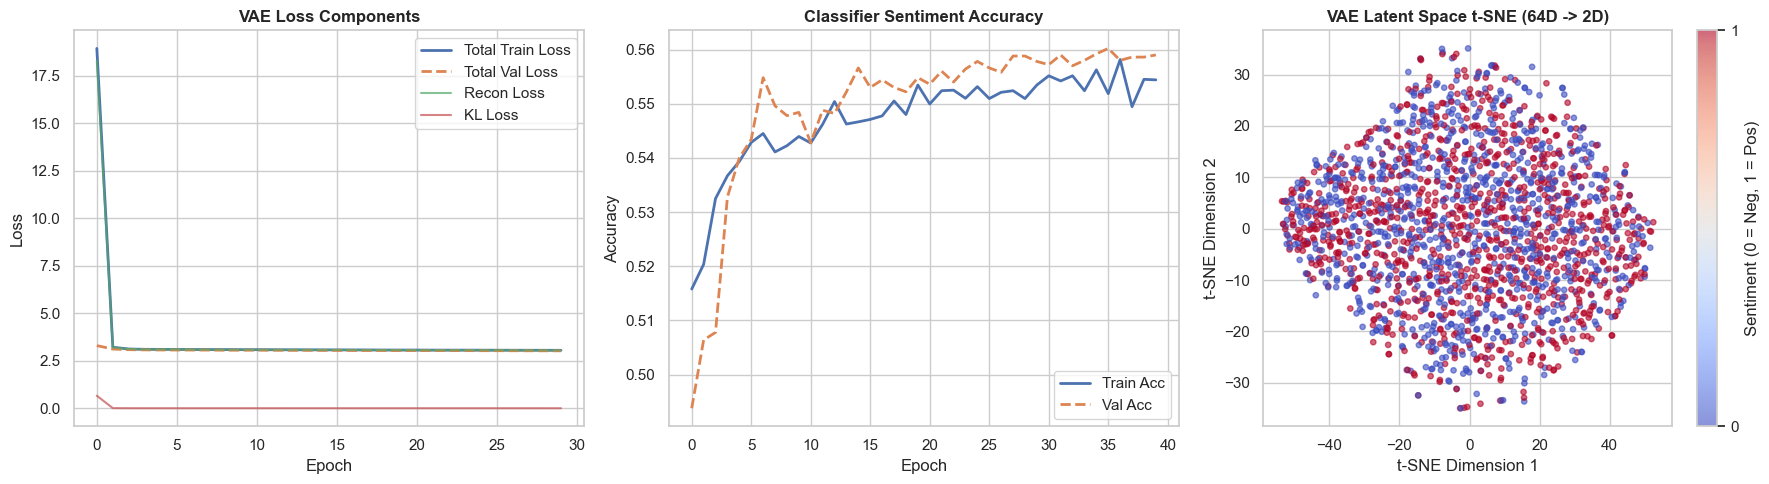

In [7]:
# ============================================================
# VAE Performance & Latent Space Visualization
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

sns.set_theme(style='whitegrid')
plt.figure(figsize=(18, 5))

# ------------------------------------------------------------
# PLOT 1: VAE Loss Components
# ------------------------------------------------------------
plt.subplot(1, 3, 1)
plt.plot(history.history['loss'], label='Total Train Loss', linewidth=2)
plt.plot(history.history['val_loss'], label='Total Val Loss', linewidth=2, linestyle='--')
if 'reconstruction_loss' in history.history:
    plt.plot(history.history['reconstruction_loss'], label='Recon Loss', alpha=0.7)
if 'kl_loss' in history.history:
    plt.plot(history.history['kl_loss'], label='KL Loss', alpha=0.7)
plt.title('VAE Loss Components', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# ------------------------------------------------------------
# PLOT 2: Classifier Accuracy & Loss
# ------------------------------------------------------------
plt.subplot(1, 3, 2)
plt.plot(history_cls.history['accuracy'], label='Train Acc', linewidth=2)
plt.plot(history_cls.history['val_accuracy'], label='Val Acc', linewidth=2, linestyle='--')
plt.title('Classifier Sentiment Accuracy', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# ------------------------------------------------------------
# PLOT 3: 2D t-SNE Projection of VAE Latent Bottleneck (64D -> 2D)
# ------------------------------------------------------------
plt.subplot(1, 3, 3)
print("Computing t-SNE projection on 2,000 test samples...")

sample_idx = np.random.choice(len(X_test_encoded), size=2000, replace=False)
X_sample = X_test_encoded[sample_idx]
y_sample = y_test[sample_idx]

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_sample)

scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=y_sample,
    cmap='coolwarm',
    alpha=0.6,
    s=15
)
plt.colorbar(scatter, ticks=[0, 1], label='Sentiment (0 = Neg, 1 = Pos)')
plt.title('VAE Latent Space t-SNE (64D -> 2D)', fontsize=12, fontweight='bold')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')

plt.tight_layout()
plt.show()